## Del 1

In [8]:
# imports
import numpy as np
import matplotlib.pyplot as plt
import scipy

In [9]:
# Overfør matrisen fra papir. Hver innerste liste er EN RAD.
# Kolonnene er avsendersider, selv om vi skriver matrisen radvis i Python.
names = list("ABCDEF")
u0 = np.ones(6) / 6
S = np.array([
    [0., 0., 1., 0., 0., 0.],  # sannsynligheter for å komme til A
    [0.5, 0., 0., 0., 0., 0.],
    [0.5, 0.5, 0., 0.5, 0., 0.],
    [0., 0.5, 0., 0., 0., 1.],
    [0., 0., 0., 0.5, 0., 0.],
    [0., 0., 0., 0., 1., 0.],
])

# Disse kontrollene avslører feil summer, men ikke alle feilplasserte lenker.
assert S.shape == (6, 6) and np.all(S >= 0)
assert np.allclose(S.sum(axis=0), 1), "Fyll inn S og kontroller hver avsenderkolonne."
print("Fordelingen etter ett steg:", S @ u0)
# Sammenlign med håndberegningen. Ikke normaliser bort en feil i matrisen.

Fordelingen etter ett steg: [0.16666667 0.08333333 0.25       0.25       0.08333333 0.16666667]


## Del 2

In [10]:
# b
def visit_step(S, alpha, u, p):
    p = alpha * S @ p  + (1 - alpha) * u # regner neste steg (verdi fordeling p)
    return p

def residual_norm(S, alpha, u, p):
    res = visit_step(S, alpha, u, p) - p # residualen, vektor av endringen av fordelingen
    res_norm = np.linalg.norm(res, 1) # normen av residualen, sum av abs verdier til residualen
    return res_norm

# Ferdig støttefunksjon: forutsetter gyldige sannsynlighetsvektorer,
# kolonnestokastisk S og 0 < alpha < 1. Den endrer ikke p0.
def pagerank(S, alpha, u, p0, error_goal=1e-8, max_steps=10000):
    p = np.array(p0, dtype=float, copy=True)
    residuals = []
    # Grensen fra 5.6 gjør residualkravet til en garanti for faktisk feil.
    tolerance = (1-alpha) * error_goal
    for k in range(max_steps + 1):
        r = float(residual_norm(S, alpha, u, p))
        residuals.append(r)
        if r <= tolerance:
            return p, np.array(residuals), True
        if k < max_steps:
            p = visit_step(S, alpha, u, p)
    return p, np.array(residuals), False

def direct_rank(S, alpha, u):
    # Sammenlign systemet i denne linjen med din utledning i del a.
    return np.linalg.solve(np.eye(len(u)) - alpha*S, (1-alpha)*u)

In [11]:
alpha = 0.85
p_ref = direct_rank(S, alpha, u0)

# Samme S, alpha og u i begge metodene: bare regnemetoden varierer.
starts = {"jevn": u0, "sikker start på A": np.eye(6)[0]}
print("Start | steg | residualnorm | feil mot direkte løsning | stoppkrav nådd")
for label, p_start in starts.items():
    p, history, converged = pagerank(S, alpha, u0, p_start)
    error = np.linalg.norm(p - p_ref, 1)
    print(label, len(history)-1, history[-1], error, converged)

print("Side | PageRank-verdi")
for j in np.argsort(-p_ref):
    print(names[j], round(p_ref[j], 3))

Start | steg | residualnorm | feil mot direkte løsning | stoppkrav nådd
jevn 51 1.3824782429949778e-09 1.0375733189293967e-09 True
sikker start på A 54 1.2103966995358206e-09 7.37080271817625e-10 True
Side | PageRank-verdi
C 0.254
A 0.241
D 0.171
B 0.128
F 0.108
E 0.098


# Del 3

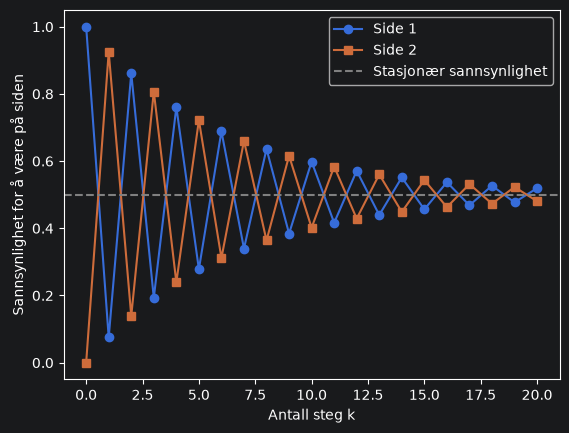

p1 og p2: [0.075 0.925] [0.86125 0.13875]


In [12]:
# Kontroller den håndutledede formelen; her er S2 allerede oppgitt.
S2 = np.array([[0., 1.], [1., 0.]])
u2 = np.array([0.5, 0.5])
alpha2 = 0.85
p2 = np.array([1., 0.])
values2 = [p2.copy()]
for k in range(20):
    p2 = visit_step(S2, alpha2, u2, p2)
    values2.append(p2.copy())
values2 = np.array(values2)

# Begge koordinatene skal nærme seg den stasjonære fordelingen.
plt.figure()
plt.plot(np.arange(21), values2[:, 0], 'o-', label="Side 1")
plt.plot(np.arange(21), values2[:, 1], 's-', label="Side 2")
plt.axhline(0.5, color="gray", linestyle="--", label="Stasjonær sannsynlighet")
plt.xlabel("Antall steg k")
plt.ylabel("Sannsynlighet for å være på siden")
plt.legend()
plt.show()
# Bruk din formel til å kontrollere verdiene ved k=1 og k=2.
print("p1 og p2:", values2[1], values2[2])

# Del 4

Side | p(0) | p(1)
A 0.24126766569470803 0.27517760864107227
B 0.12753875792025093 0.1319504836724557
C 0.2544325478761271 0.3060913042836144
D 0.1710348655053401 0.1366161530596824
E 0.09768981783976954 0.07306186505036502
F 0.1080363451638041 0.07710258529281028


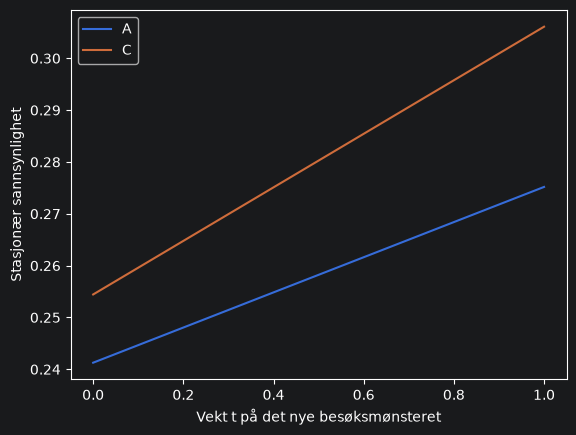

t | forskjell mellom sidene | avvik fra blandingsformelen
0.25 -0.01760208554669987 9.71445146547012e-17
0.75 -0.0264764922772614 5.551115123125783e-17


In [13]:
# Startforslag: hopp oftere til C.
# Påstand: C får større verdi en A
# Du kan bruke forslaget hvis det svarer til påstanden du vil undersøke.
u1 = np.array([0.1, 0.1, 0.5, 0.1, 0.1, 0.1])
pair = ("A", "C")  # Velg to forskjellige sider FØR kjøring.

assert u1.shape == u0.shape and np.all(u1 > 0) and np.isclose(u1.sum(), 1)
assert not np.allclose(u1, u0), "Velg et annet besøksmønster enn jevne hopp."
assert pair[0] != pair[1] and all(name in names for name in pair)
i, j = (names.index(name) for name in pair)
alpha = 0.85
p_left = direct_rank(S, alpha, u0)   # p(0), en stasjonær løsning
p_right = direct_rank(S, alpha, u1)  # p(1), en annen stasjonær løsning
print("Side | p(0) | p(1)")
for name, left, right in zip(names, p_left, p_right):
    print(name, left, right)

# Endepunktene bestemmer de rette linjene. Kontroller formelen matematisk!
t_plot = np.linspace(0, 1, 101)
p_blend = (1-t_plot[:, None])*p_left + t_plot[:, None]*p_right
plt.figure()
plt.plot(t_plot, p_blend[:, i], label=pair[0])
plt.plot(t_plot, p_blend[:, j], label=pair[1])
plt.xlabel("Vekt t på det nye besøksmønsteret")
plt.ylabel("Stasjonær sannsynlighet")
plt.legend()
plt.show()

# Endre kontrollpunktene ut fra din matematisk bestemte terskel.
# De direkte løsningene er en kontroll, ikke en leting etter terskelen.
t_checks = [0.25, 0.75]
print("t | forskjell mellom sidene | avvik fra blandingsformelen")
for t in t_checks:
    assert 0 <= t <= 1
    u_t = (1-t)*u0 + t*u1
    p_direct = direct_rank(S, alpha, u_t)
    predicted = (1-t)*p_left + t*p_right
    print(t, p_direct[i]-p_direct[j], np.linalg.norm(p_direct-predicted, 1))